In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

# Configuración estética
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# Cargar el dataset (ajusta la ruta si es necesario)
df = pd.read_csv("../results/reports/predictions_discovery_reports/Full_Dataset_Predictions.csv")

print(f"Dataset cargado: {len(df):,} péptidos.")

Dataset cargado: 1,282,383 péptidos.


In [2]:
def plot_top_patients(threshold, top_n_patients):
    # 1. Filtrar por el umbral de probabilidad seleccionado
    df_positives = df[df['Immunogenicity_Probability'] >= threshold]
    
    # 2. Contar neoantígenos por paciente
    patient_counts = df_positives['patient'].value_counts().reset_index()
    patient_counts.columns = ['patient', 'neoantigen_count']
    
    # 3. Cruzar con la cohorte para mantener el color por grupo en la gráfica
    # (Asumimos que la columna 'cohort' ya está en tu Full_Dataset_Predictions.csv)
    cohort_map = df[['patient', 'cohort']].drop_duplicates().set_index('patient')
    patient_counts['cohort'] = patient_counts['patient'].map(cohort_map['cohort'])
    
    # 4. Tomar los mejores N pacientes
    plot_df = patient_counts.head(top_n_patients)
    
    # 5. Crear la figura
    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=plot_df, 
        x='neoantigen_count', 
        y='patient', 
        hue='cohort', 
        palette='viridis',
        edgecolor='black'
    )
    
    plt.title(f'Top {top_n_patients} Pacientes con más Neoantígenos (Umbral > {threshold:.2f})', fontsize=15)
    plt.xlabel('Número de Neoantígenos Potencialmente Inmunogénicos', fontsize=12)
    plt.ylabel('ID del Paciente', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.legend(title='Cohorte', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

# Crear los controles interactivos
widgets.interact(
    plot_top_patients, 
    threshold=widgets.FloatSlider(min=0.1, max=0.95, step=0.05, value=0.5, description='Umbral Prob:'),
    top_n_patients=widgets.IntSlider(min=5, max=50, step=5, value=20, description='Top Pacientes:')
);

interactive(children=(FloatSlider(value=0.5, description='Umbral Prob:', max=0.95, min=0.1, step=0.05), IntSli…

In [3]:
import pandas as pd
import numpy as np

# 1. Cargar tu clínica principal (como ya hacías)
df_au = pd.read_csv('../data/raw/donor_APGI.tsv', sep='\t')
df_ca = pd.read_csv('../data/raw/donor_PACA.tsv', sep='\t')
df_clinico = pd.concat([df_au, df_ca], ignore_index=True)

df_clinico['ID_Paciente'] = 'DO' + df_clinico['donor_id'].astype(str)
df_clinico['Tiempo'] = pd.to_numeric(df_clinico['survival_time'], errors='coerce')
df_clinico['Supervivencia'] = np.where(df_clinico['vital_status'] == 'Deceased', 1, 0)
df_clinico.loc[df_clinico['vital_status'].isna(), 'Supervivencia'] = np.nan

# ==============================================================================
# ¡NUEVO! RESCATE DE PACIENTES VIVOS USANDO FOLLOW_UP
# ==============================================================================
# Cargar el archivo de follow_up
df_follow = pd.read_csv('../data/raw/follow_up_APGI.tsv', sep='\t')
df_follow_PACA = pd.read_csv('../data/raw/follow_up_PACA.tsv', sep='\t')
df_follow = pd.concat([df_follow, df_follow_PACA], ignore_index=True)

# Asegurar que los días son numéricos
df_follow['interval_of_followup'] = pd.to_numeric(df_follow['interval_of_followup'], errors='coerce')

# Un paciente puede tener varias visitas. Nos quedamos con el último día que se le vio (el máximo)
ultimos_seguimientos = df_follow.groupby('donor_id')['interval_of_followup'].max().reset_index()

# Formatear el ID para que cruce con nuestro dataset clínico
ultimos_seguimientos['ID_Paciente'] = 'DO' + ultimos_seguimientos['donor_id'].astype(str)
ultimos_seguimientos.rename(columns={'interval_of_followup': 'Tiempo_FollowUp'}, inplace=True)

# Cruzamos la información con el dataset clínico
df_clinico = pd.merge(df_clinico, ultimos_seguimientos[['ID_Paciente', 'Tiempo_FollowUp']], on='ID_Paciente', how='left')

# El momento de la magia: Si el 'Tiempo' es NaN (porque estaba vivo), usamos el 'Tiempo_FollowUp'
df_clinico['Tiempo'] = df_clinico['Tiempo'].fillna(df_clinico['Tiempo_FollowUp'])

# Ahora sí, eliminamos los que definitivamente no tienen ni survival_time ni follow_up
df_clinico = df_clinico.dropna(subset=['Tiempo', 'Supervivencia'])

print(f"Pacientes totales con datos de tiempo tras el rescate: {len(df_clinico)}")

Pacientes totales con datos de tiempo tras el rescate: 209


Pacientes finales para el análisis: 118


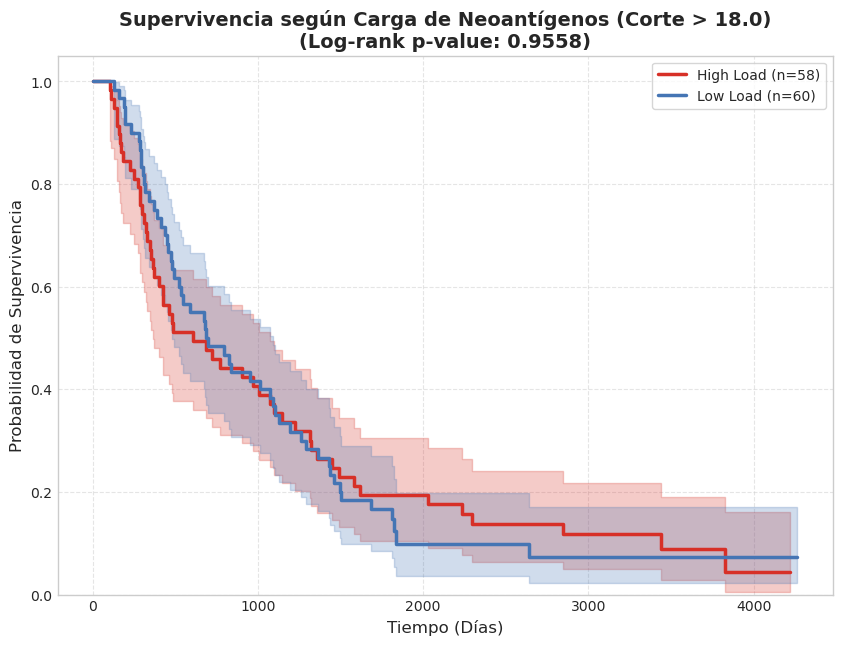

In [4]:
import pandas as pd
import numpy as np
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CARGAR DATOS CLÍNICOS Y RESCATAR PACIENTES VIVOS
# ==============================================================================
df_au = pd.read_csv('../data/raw/donor_APGI.tsv', sep='\t')
df_ca = pd.read_csv('../data/raw/donor_PACA.tsv', sep='\t')
df_clinico = pd.concat([df_au, df_ca], ignore_index=True)

df_clinico['ID_Paciente'] = 'DO' + df_clinico['donor_id'].astype(str)
df_clinico['Tiempo'] = pd.to_numeric(df_clinico['survival_time'], errors='coerce')
df_clinico['Supervivencia'] = np.where(df_clinico['vital_status'] == 'Deceased', 1, 0)
df_clinico.loc[df_clinico['vital_status'].isna(), 'Supervivencia'] = np.nan

# Archivos de seguimiento (Follow up) para rescatar tiempos
df_follow_au = pd.read_csv('../data/raw/follow_up_APGI.tsv', sep='\t')
df_follow_ca = pd.read_csv('../data/raw/follow_up_PACA.tsv', sep='\t')
df_follow = pd.concat([df_follow_au, df_follow_ca], ignore_index=True)

df_follow['interval_of_followup'] = pd.to_numeric(df_follow['interval_of_followup'], errors='coerce')
ultimos_seguimientos = df_follow.groupby('donor_id')['interval_of_followup'].max().reset_index()
ultimos_seguimientos['ID_Paciente'] = 'DO' + ultimos_seguimientos['donor_id'].astype(str)
ultimos_seguimientos.rename(columns={'interval_of_followup': 'Tiempo_FollowUp'}, inplace=True)

df_clinico = pd.merge(df_clinico, ultimos_seguimientos[['ID_Paciente', 'Tiempo_FollowUp']], on='ID_Paciente', how='left')
df_clinico['Tiempo'] = df_clinico['Tiempo'].fillna(df_clinico['Tiempo_FollowUp'])
df_clinico = df_clinico.dropna(subset=['Tiempo', 'Supervivencia'])

# ==============================================================================
# 2. CALCULAR CARGA INMUNOGÉNICA (Conteo clásico, sin ponderar)
# ==============================================================================
umbral = 0.7

# Lista de TODOS los pacientes en las predicciones
todos_los_pacientes = pd.DataFrame({'ID_Paciente': df['patient'].unique()})

# Filtramos los péptidos que superan el umbralç
df_positivos = df[df['Immunogenicity_Probability'] >= umbral]

# Conteo simple de cuántos neoantígenos tiene cada paciente (usamos .size())
neo_load_raw = df_positivos.groupby('patient').size().reset_index(name='Neoantigen_Load')
neo_load_raw.columns = ['ID_Paciente', 'Neoantigen_Load']

# Unimos para no perder a los pacientes con carga 0
neo_load = pd.merge(todos_los_pacientes, neo_load_raw, on='ID_Paciente', how='left')
neo_load['Neoantigen_Load'] = neo_load['Neoantigen_Load'].fillna(0)

# ==============================================================================
# 3. CRUZAR Y CREAR GRUPOS (High vs Low Load)
# ==============================================================================
df_survival = pd.merge(df_clinico, neo_load, on='ID_Paciente', how='inner')
print(f"Pacientes finales para el análisis: {len(df_survival)}")

# Usamos la mediana como punto de corte
corte = df_survival['Neoantigen_Load'].median()
df_survival['Group'] = np.where(df_survival['Neoantigen_Load'] > corte, 'High Load', 'Low Load')

# ==============================================================================
# 4. FIGURA KAPLAN-MEIER
# ==============================================================================
kmf = KaplanMeierFitter()
plt.figure(figsize=(10, 7))

# Colores personalizados para distinguirlos bien
colores = {'High Load': '#d73027', 'Low Load': '#4575b4'}

for name, grouped_df in df_survival.groupby('Group'):
    kmf.fit(grouped_df['Tiempo'], grouped_df['Supervivencia'], label=f"{name} (n={len(grouped_df)})")
    kmf.plot_survival_function(ci_show=True, linewidth=2.5, color=colores[name]) 

# Test estadístico
high = df_survival[df_survival['Group'] == 'High Load']
low = df_survival[df_survival['Group'] == 'Low Load']

results = logrank_test(high['Tiempo'], low['Tiempo'], high['Supervivencia'], low['Supervivencia'])

# Formato de la gráfica
plt.title(f'Supervivencia según Carga de Neoantígenos (Corte > {corte})\n(Log-rank p-value: {results.p_value:.4f})', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo (Días)', fontsize=12)
plt.ylabel('Probabilidad de Supervivencia', fontsize=12)
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True)
plt.show()

## Análisis Básicos y AFT (Lifelines)

In [5]:
# =============================================================================
# 1. PREPARACIÓN DEL MARCADOR BINARIO Y MODELOS BASE (COX & AFT)
# =============================================================================
from lifelines import CoxPHFitter, LogNormalAFTFitter
import numpy as np

# Creamos el marcador binario X basado en tu clasificación (1 = High Load, 0 = Low Load)
df_survival['X'] = np.where(df_survival['Group'] == 'High Load', 1, 0)

# 1. Modelo de Cox Univariante
print("--- MODELO DE RIESGOS PROPORCIONALES DE COX ---")
cph = CoxPHFitter()
cph.fit(df_survival[['Tiempo', 'Supervivencia', 'X']], duration_col='Tiempo', event_col='Supervivencia')
cph.print_summary()

# 2. Modelo de Tiempo Acelerado (AFT) con distribución Log-Normal
# Útil si no se cumple el supuesto de proporcionalidad de Cox
print("\n--- MODELO DE TIEMPO ACELERADO (LOG-NORMAL AFT) ---")
aft = LogNormalAFTFitter()
aft.fit(df_survival[['Tiempo', 'Supervivencia', 'X']], duration_col='Tiempo', event_col='Supervivencia')
aft.print_summary()

--- MODELO DE RIESGOS PROPORCIONALES DE COX ---


<lifelines.CoxPHFitter: fitted with 118 total observations, 12 right-censored observations>
             duration col = 'Tiempo'
                event col = 'Supervivencia'
      baseline estimation = breslow
   number of observations = 118
number of events observed = 106
   partial log-likelihood = -422.44
         time fit was run = 2026-03-19 09:15:43 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
X          0.01      1.01      0.20           -0.37            0.39                0.69                1.48

           cmp to    z    p  -log2(p)
covariate                            
X            0.00 0.05 0.96      0.06
---
Concordance = 0.52
Partial AIC = 846.87
log-likelihood ratio test = 0.00 on 1 df
-log2(p) of ll-ratio test = 0.06


--- MODELO DE TIEMPO ACELERADO (LOG-NORMAL AFT) ---


<lifelines.LogNormalAFTFitter: fitted with 118 total observations, 12 right-censored observations>
             duration col = 'Tiempo'
                event col = 'Supervivencia'
   number of observations = 118
number of events observed = 106
           log-likelihood = -841.91
         time fit was run = 2026-03-19 09:15:43 UTC

---
                  coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param  covariate                                                                                                  
mu_    X         -0.11      0.89      0.19           -0.48            0.26                0.62                1.29
       Intercept  6.63    760.26      0.13            6.38            6.89              587.04              984.59
sigma_ Intercept  0.01      1.01      0.07           -0.13            0.15                0.88                1.16

                  cmp to     z      p  -log2(p)
param  covariate                               
mu_    X            0.00 -0.60   0.55      0.87
       Intercept    0.00 50.28 <0.005       inf
sigma_ Intercept    0.00  0.17   0.87      0.21
---
Concordance = 0.52
AIC = 1689.82
log-likelihood ratio test = 0.36 on 1 df
-log2(p) of ll-ratio test = 0.87

## Regresión Logística y Landmark Analysis

In [6]:
# =============================================================================
# 2. REGRESIÓN LOGÍSTICA PARA LONG-SURVIVAL & LANDMARK ANALYSIS
# =============================================================================
import statsmodels.api as sm

# Definir "long-survival" (ej: > 730 días / ~24 meses)
df_survival['long_surv'] = np.where(df_survival['Tiempo'] > 730, 1, 0)

# Regresión Logística
print("--- REGRESIÓN LOGÍSTICA PARA SUPERVIVENCIA > 24 MESES ---")
X_logit = sm.add_constant(df_survival['X'])
logit_model = sm.Logit(df_survival['long_surv'], X_logit).fit(disp=0)
print(logit_model.summary())

# Landmark Analysis (Pacientes que sobreviven más de 12 meses / ~365 días)
print("\n--- LANDMARK ANALYSIS (Condicionado a sobrevivir > 12 meses) ---")
landmark_time = 365
df_landmark = df_survival[df_survival['Tiempo'] > landmark_time].copy()
df_landmark['Tiempo_Landmark'] = df_landmark['Tiempo'] - landmark_time

cph_landmark = CoxPHFitter()
cph_landmark.fit(df_landmark[['Tiempo_Landmark', 'Supervivencia', 'X']], duration_col='Tiempo_Landmark', event_col='Supervivencia')
cph_landmark.print_summary()

--- REGRESIÓN LOGÍSTICA PARA SUPERVIVENCIA > 24 MESES ---
                           Logit Regression Results                           
Dep. Variable:              long_surv   No. Observations:                  118
Model:                          Logit   Df Residuals:                      116
Method:                           MLE   Df Model:                            1
Date:                Thu, 19 Mar 2026   Pseudo R-squ.:               0.0008936
Time:                        10:15:44   Log-Likelihood:                -81.447
converged:                       True   LL-Null:                       -81.520
Covariance Type:            nonrobust   LLR p-value:                    0.7027
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0667      0.258     -0.258      0.796      -0.573       0.440
X             -0.1409      0.369     -0.382      0.703      -0.865       

<lifelines.CoxPHFitter: fitted with 82 total observations, 11 right-censored observations>
             duration col = 'Tiempo_Landmark'
                event col = 'Supervivencia'
      baseline estimation = breslow
   number of observations = 82
number of events observed = 71
   partial log-likelihood = -260.65
         time fit was run = 2026-03-19 09:15:44 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
X         -0.25      0.78      0.24           -0.73            0.22                0.48                1.25

           cmp to     z    p  -log2(p)
covariate                             
X            0.00 -1.05 0.30      1.76
---
Concordance = 0.53
Partial AIC = 523.29
log-likelihood ratio test = 1.10 on 1 df
-log2(p) of ll-ratio test = 1.77

## Restricted Mean Survival Time (RMST)

In [7]:
# =============================================================================
# 3. RESTRICTED MEAN SURVIVAL TIME (RMST) A 36 MESES
# =============================================================================
from lifelines.utils import restricted_mean_survival_time

horizonte_dias = 1095 # ~36 meses

kmf_high = KaplanMeierFitter().fit(df_survival[df_survival['X']==1]['Tiempo'], df_survival[df_survival['X']==1]['Supervivencia'])
kmf_low = KaplanMeierFitter().fit(df_survival[df_survival['X']==0]['Tiempo'], df_survival[df_survival['X']==0]['Supervivencia'])

rmst_high = restricted_mean_survival_time(kmf_high, t=horizonte_dias)
rmst_low = restricted_mean_survival_time(kmf_low, t=horizonte_dias)

print(f"RMST High Load (Área bajo la curva hasta {horizonte_dias} días): {rmst_high:.1f} días")
print(f"RMST Low Load (Área bajo la curva hasta {horizonte_dias} días): {rmst_low:.1f} días")
print(f"Diferencia: {abs(rmst_high - rmst_low):.1f} días")

RMST High Load (Área bajo la curva hasta 1095 días): 664.9 días
RMST Low Load (Área bajo la curva hasta 1095 días): 718.3 días
Diferencia: 53.4 días


## Random Survival Forest (RSF)

In [8]:
# =============================================================================
# 4. RANDOM SURVIVAL FORESTS 
# =============================================================================
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

# Scikit-Survival requiere que el target sea un array estructurado de booleanos y floats
df_survival['Status_Bool'] = df_survival['Supervivencia'].astype(bool)
y = Surv.from_dataframe('Status_Bool', 'Tiempo', df_survival)

# Variables predictoras (Añade estadio, CA19-9, etc., si los tienes en df_survival)
X_ml = df_survival[['X']] 

# Entrenar Random Survival Forest
rsf = RandomSurvivalForest(n_estimators=1000, min_samples_split=10, min_samples_leaf=15, random_state=42)
rsf.fit(X_ml, y)

print(f"Índice de Concordancia (C-index) del RSF: {rsf.score(X_ml, y):.4f}")

Índice de Concordancia (C-index) del RSF: 0.5194


In [9]:
# =============================================================================
# 1. CONSTRUIR LA TABLA MAESTRA POR PACIENTE (Versión NetMHCpan)
# =============================================================================
import pandas as pd
import numpy as np

# Tu columna de NetMHCpan
col_rank = 'mutant_rank_netMHCpan'

def calculate_metrics(g):
    metrics = {}
    metrics['n_neoantigens'] = len(g)
    
    # Calcular Mediana del Rank y Proporción de Strong Binders (< 0.5%)
    if col_rank in g.columns:
        metrics['median_Rank'] = g[col_rank].median()
        metrics['prop_strong_binders'] = (g[col_rank] < 0.5).mean() 
    else:
        metrics['median_Rank'] = np.nan
        metrics['prop_strong_binders'] = np.nan
        
    return pd.Series(metrics)

# Aplicar a los neoantígenos positivos (manteniendo tu umbral >= 0.7 de pasos anteriores)
df_positivos = df[df['Immunogenicity_Probability'] >= 0.7]
df_metrics = df_positivos.groupby('patient').apply(calculate_metrics).reset_index()
df_metrics.rename(columns={'patient': 'ID_Paciente'}, inplace=True)

# Cruzar con los datos de supervivencia
df_master = pd.merge(df_survival[['ID_Paciente', 'Tiempo', 'Supervivencia']], df_metrics, on='ID_Paciente', how='inner')

# Convertir días a meses para que sea más fácil de interpretar (OS_months)
df_master['OS_months'] = df_master['Tiempo'] / 30.44

print(f"Tabla maestra creada. Pacientes totales: {len(df_master)}")
display(df_master.head(3))

Tabla maestra creada. Pacientes totales: 118


/tmp/ipykernel_11614/2493966291.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_metrics = df_positivos.groupby('patient').apply(calculate_metrics).reset_index()


,ID_Paciente,Tiempo,Supervivencia,n_neoantigens,median_Rank,prop_strong_binders,OS_months
0,DO32825,2848.0,1.0,19.0,1.6225,0.105263,93.561104
1,DO32831,2237.0,1.0,19.0,1.0487,0.263158,73.488830
2,DO32837,399.0,1.0,25.0,2.1067,0.200000,13.107753


In [10]:
# =============================================================================
# 2. DEFINIR GRUPOS LONG VS SHORT SURVIVORS (Q1 vs Q4)
# =============================================================================

# Cuantiles extremos de supervivencia
q25 = df_master['OS_months'].quantile(0.25)
q75 = df_master['OS_months'].quantile(0.75)

print(f"Corte Q1 (Short Survivors) <= {q25:.1f} meses")
print(f"Corte Q4 (Long Survivors) >= {q75:.1f} meses")

# Asignar grupos
df_master['group'] = np.nan
df_master.loc[df_master['OS_months'] <= q25, 'group'] = 'short'
df_master.loc[df_master['OS_months'] >= q75, 'group'] = 'long'

# Trabajar solo con los extremos (quitamos el Q2 y Q3 del medio)
df_ext = df_master[df_master['group'].notna()].copy()

print(f"Pacientes en grupo 'Short': {sum(df_ext['group'] == 'short')}")
print(f"Pacientes en grupo 'Long': {sum(df_ext['group'] == 'long')}")

Corte Q1 (Short Survivors) <= 10.4 meses
Corte Q4 (Long Survivors) >= 47.1 meses
Pacientes en grupo 'Short': 30
Pacientes en grupo 'Long': 30


/tmp/ipykernel_11614/3615883523.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'short' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_master.loc[df_master['OS_months'] <= q25, 'group'] = 'short'


In [11]:
# =============================================================================
# 3. TESTS ESTADÍSTICOS (MANN-WHITNEY Y SPEARMAN) + CORRECCIÓN FDR
# =============================================================================
from scipy.stats import mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests

long_group = df_ext[df_ext['group'] == 'long']
short_group = df_ext[df_ext['group'] == 'short']

# Quitamos prop_clonal y usamos median_Rank
metrics_to_test = ['n_neoantigens', 'median_Rank', 'prop_strong_binders']
results = []

for metric in metrics_to_test:
    if df_master[metric].notna().sum() > 0: # Verificar que la métrica tenga datos
        
        # Mann-Whitney U Test (Solo extremos Q1 vs Q4)
        stat_mw, p_mw = mannwhitneyu(long_group[metric].dropna(), short_group[metric].dropna(), alternative='two-sided')
        
        # Spearman Correlation (Toda la cohorte continua)
        stat_sp, p_sp = spearmanr(df_master['OS_months'], df_master[metric], nan_policy='omit')
        
        results.append({
            'Métrica': metric,
            'Mediana_Long': long_group[metric].median(),
            'Mediana_Short': short_group[metric].median(),
            'Mann-Whitney_U': stat_mw,
            'p_value_MW': p_mw,
            'Spearman_R': stat_sp,
            'p_value_Spearman': p_sp
        })

df_results = pd.DataFrame(results)

# Corrección por múltiples comparaciones (Benjamini-Hochberg FDR)
if not df_results.empty:
    reject, p_adj, _, _ = multipletests(df_results['p_value_MW'], method='fdr_bh')
    df_results['p_adj_MW (FDR)'] = p_adj

print("--- TABLA RESUMEN DE RESULTADOS ---")
display(df_results)

--- TABLA RESUMEN DE RESULTADOS ---


,Métrica,Mediana_Long,Mediana_Short,Mann-Whitney_U,p_value_MW,Spearman_R,p_value_Spearman,p_adj_MW (FDR)
0,n_neoantigens,18.500000,21.500000,393.5,0.407235,-0.126533,0.172138,0.610853
1,median_Rank,1.615400,1.351850,570.0,0.077272,0.148435,0.108680,0.231816
2,prop_strong_binders,0.217483,0.222222,416.5,0.625539,-0.068877,0.458627,0.625539


/tmp/ipykernel_11614/752860128.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ext, x='group', y=metric, order=['short', 'long'],


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

short vs. long: Mann-Whitney-Wilcoxon test two-sided, P_val:4.072e-01 U_stat=5.065e+02


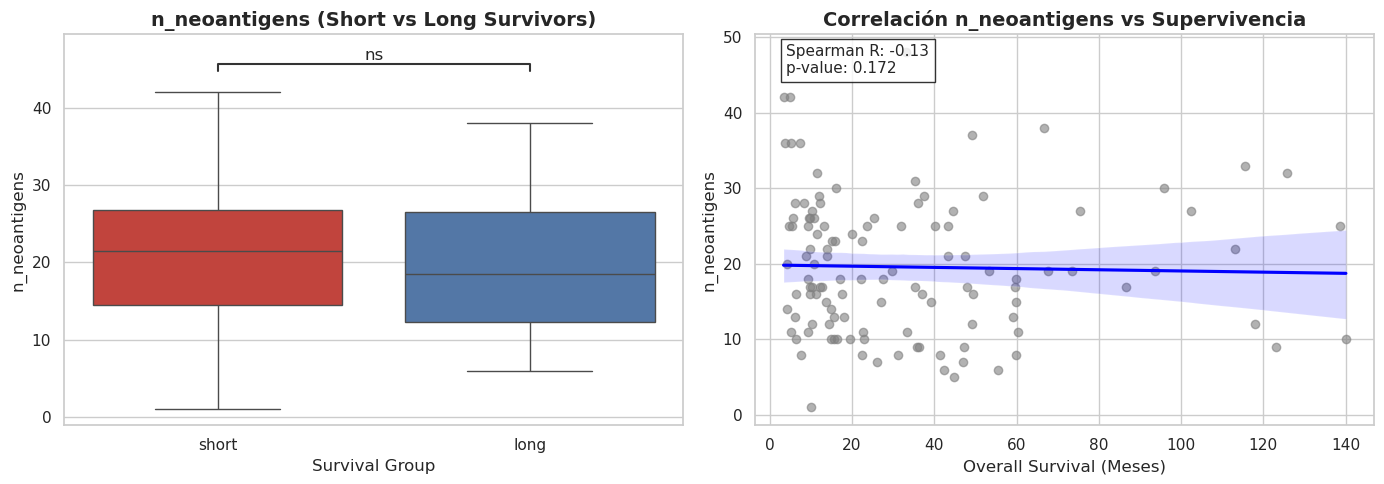

/tmp/ipykernel_11614/752860128.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ext, x='group', y=metric, order=['short', 'long'],


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

short vs. long: Mann-Whitney-Wilcoxon test two-sided, P_val:7.727e-02 U_stat=3.300e+02


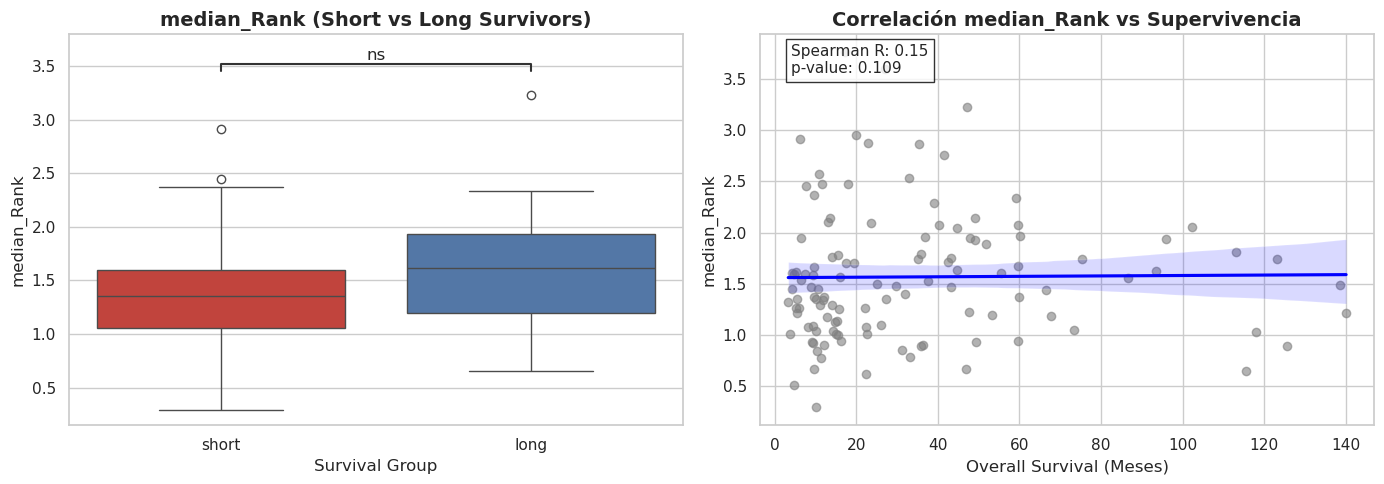

/tmp/ipykernel_11614/752860128.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ext, x='group', y=metric, order=['short', 'long'],


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

short vs. long: Mann-Whitney-Wilcoxon test two-sided, P_val:6.255e-01 U_stat=4.835e+02


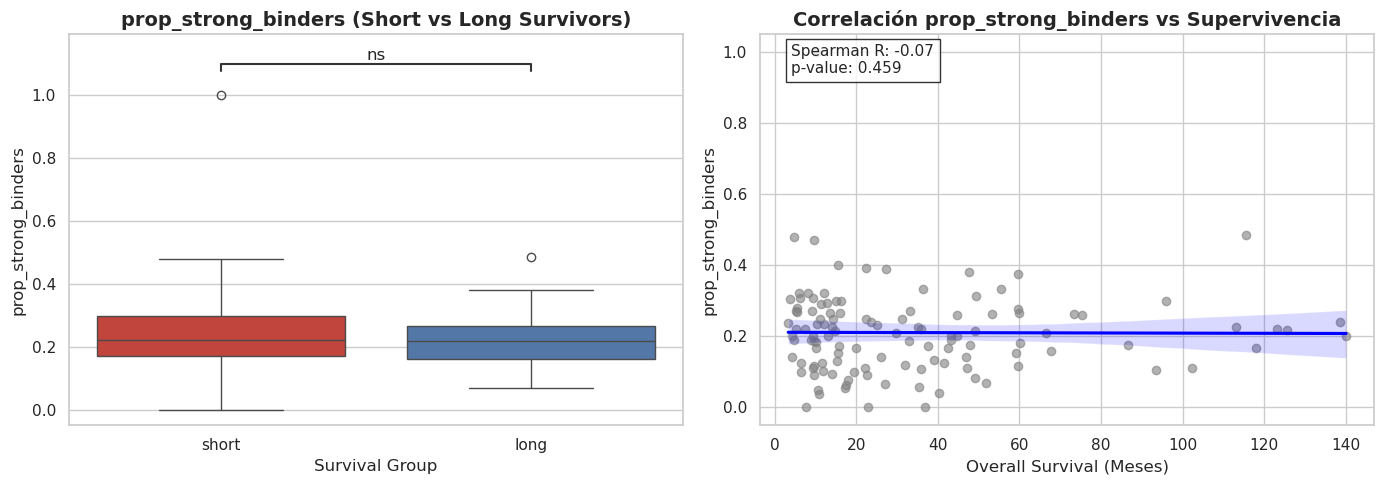

In [13]:
# =============================================================================
# 4. VISUALIZACIÓN (BOXPLOTS Y SCATTER PLOTS)
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Intentar cargar statannotations para p-valores automáticos
try:
    from statannotations.Annotator import Annotator
    has_statann = True
except ImportError:
    has_statann = False
    print("💡 statannotations no está instalado. Se usarán boxplots estándar.")
    print("Para p-valores automáticos en la gráfica ejecuta: !pip install statannotations")

sns.set_theme(style="whitegrid")

for metric in metrics_to_test:
    if df_master[metric].notna().sum() > 0:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ----- 1. Boxplot (Cuartiles Extremos) -----
        ax1 = axes[0]
        sns.boxplot(data=df_ext, x='group', y=metric, order=['short', 'long'], 
                    ax=ax1, palette={'short': '#d73027', 'long': '#4575b4'})
        ax1.set_title(f'{metric} (Short vs Long Survivors)', fontsize=14, fontweight='bold')
        ax1.set_ylabel(metric)
        ax1.set_xlabel('Survival Group')
        
        if has_statann:
            annotator = Annotator(ax1, [("short", "long")], data=df_ext, x='group', y=metric, order=['short', 'long'])
            annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
            annotator.apply_and_annotate()
            
        # ----- 2. Scatter Plot (Continua) -----
        ax2 = axes[1]
        sns.regplot(data=df_master, x='OS_months', y=metric, ax=ax2, 
                    scatter_kws={'alpha':0.6, 'color':'gray'}, line_kws={'color':'blue'})
        ax2.set_title(f'Correlación {metric} vs Supervivencia', fontsize=14, fontweight='bold')
        ax2.set_xlabel('Overall Survival (Meses)')
        
        # Añadir caja de texto con Spearman
        sp_r = df_results.loc[df_results['Métrica'] == metric, 'Spearman_R'].values[0]
        sp_p = df_results.loc[df_results['Métrica'] == metric, 'p_value_Spearman'].values[0]
        ax2.text(0.05, 0.9, f'Spearman R: {sp_r:.2f}\np-value: {sp_p:.3f}', 
                 transform=ax2.transAxes, fontsize=11,
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
        
        plt.tight_layout()
        plt.show()